# Assignment 1: Introduction to language modeling

[Official instructions](https://liu-nlp.ai/dl4nlp/units/a1_1.html)

This notebook follows Parts 1-5 and contains the implementation directly in its cells.
Run it from top to bottom in Jupyter or Colab. Select a GPU runtime in Colab for full training.
Set `QUICK_RUN=True` for an initial small run; return it to `False` for the full experiment.

## Part 0 - Task 0.1: Environment and corpus


In [2]:
# Install the packages in this notebook's Python kernel; version bounds keep the APIs compatible.
# After the first installation, restart the kernel if Jupyter asks you to.
%pip install -q "torch>=2.6,<3" "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" "nltk>=3.9,<4" "pandas>=2,<4" "matplotlib>=3.8,<4" "tqdm>=4.66" "certifi>=2024.2.2"



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Import the libraries for data preparation, neural networks, and displaying results.
import gc
import json
import math
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from tqdm.auto import tqdm
from IPython.display import display, Markdown, FileLink
from transformers import BatchEncoding, PretrainedConfig, PreTrainedModel, TrainingArguments, set_seed
from transformers.modeling_outputs import CausalLMOutput

pd.set_option('display.max_colwidth', 140)

# Use a CUDA GPU when available, otherwise Apple MPS, otherwise the CPU.
def select_device(use_cpu=False):
    if use_cpu:
        return torch.device('cpu')
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


/Users/echaefs/Documents/Code/tdde09/dl4nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Choose the dataset size, model dimensions and training settings.
# QUICK_RUN is for checking the pipeline; use False for the full experiment.
QUICK_RUN = False  # True checks a small subset; False runs the full experiment.
FORCE_CPU = False
SEED = 101
# The vocabulary cap includes PAD, UNK, BOS and EOS.
VOCAB_SIZE = 10000
# Maximum tokens per paragraph, including its boundary tokens.
MAX_LENGTH = 128
# Process this many paragraphs together in each optimizer step.
BATCH_SIZE = 32
EPOCHS = 1 if QUICK_RUN else 3
# Step size for AdamW; large values can make training unstable.
LEARNING_RATE = 3e-4
QUICK_TRAIN_SAMPLES, QUICK_VAL_SAMPLES = 1000, 200
EMBEDDING_SIZE, HIDDEN_SIZE = 128, 256
DATA_DIR = Path('dl4nlp_data')
# This folder holds the checkpoint used later by from_pretrained, plus optional logs.
OUTPUT_DIR = Path('outputs') / ('assignment1_quick' if QUICK_RUN else 'assignment1')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = select_device(FORCE_CPU)
# Fix random seeds for a repeatable run on the same setup.
set_seed(SEED)
print('Device:', DEVICE, '| Mode:', 'small subset' if QUICK_RUN else 'full experiment')


Device: mps | Mode: full experiment


In [5]:
# Download the official corpus with HTTPS certificate verification enabled.
import ssl
import certifi

# Add trusted CA certificates for Python installations without a configured CA bundle.
download_context = ssl.create_default_context()
download_context.load_verify_locations(cafile=certifi.where())

DATA_URL = 'https://www.cse.chalmers.se/~richajo/waspnlp2026/a1_1.zip'
# Keep training and validation text separate; vocabulary statistics use training text only.
TRAIN_FILE, VAL_FILE = DATA_DIR / 'train.txt', DATA_DIR / 'val.txt'
if not TRAIN_FILE.exists() or not VAL_FILE.exists():
    archive_path = DATA_DIR / 'a1_1.zip'
    if not archive_path.exists():
        print('Downloading the official corpus...')
        with urllib.request.urlopen(DATA_URL, timeout=60, context=download_context) as response:
            archive_path.write_bytes(response.read())
    # Extract the two text files; rerunning the cell reuses files already downloaded.
    with zipfile.ZipFile(archive_path) as archive:
        for name in ('train.txt', 'val.txt'):
            (DATA_DIR / name).write_bytes(archive.read(f'a1_1/{name}'))
print('Training file:', TRAIN_FILE)
print('Validation file:', VAL_FILE)


Training file: dl4nlp_data/train.txt
Validation file: dl4nlp_data/val.txt


## Part 1: Tokenization
### Task 1.1: Word splitting
Text is lowercased after NLTK word splitting. Each paragraph is already one example,
so `preserve_line=True` avoids a separate sentence-tokenizer download.


In [6]:
# Split text into word/punctuation tokens and lowercase them to reduce vocabulary variation.
def lowercase_tokenizer(text):
    # Paragraphs are already separate examples, so no sentence model is needed.
    return [word.lower() for word in nltk.word_tokenize(text, preserve_line=True)]

print(lowercase_tokenizer("Let's test!!"))


['let', "'s", 'test', '!', '!']


### Task 1.2: Building the vocabulary
Count tokens in the training text only. Reserve four IDs and keep the most frequent
remaining words up to the vocabulary cap. Validation text never affects the vocabulary.


In [7]:
# Learn a fixed vocabulary from training text and create the tokenizer that uses it.
def build_tokenizer(train_file, tokenize_fun=lowercase_tokenizer,
                    max_voc_size=10000, model_max_length=128,
                    pad_token='<PAD>', unk_token='<UNK>',
                    bos_token='<BOS>', eos_token='<EOS>'):
    special = [pad_token, unk_token, bos_token, eos_token]
    if len(set(special)) != 4:
        raise ValueError('The four special tokens must be distinct.')
    if max_voc_size is not None and max_voc_size < 4:
        raise ValueError('max_voc_size must allow the four special tokens.')
    # Count each word in the training corpus; frequent words receive vocabulary entries.
    counts = Counter()
    with open(train_file, encoding='utf-8') as stream:
        for line in tqdm(stream, desc='Building training vocabulary'):
            if line.strip():
                counts.update(tokenize_fun(line))
    # Avoid assigning an ordinary-word entry to a reserved special token.
    for token in special:
        counts.pop(token, None)
    # Reserve four slots before choosing the most frequent ordinary words.
    limit = None if max_voc_size is None else max_voc_size - 4
    words = special + [word for word, _ in counts.most_common(limit)]
    return A1Tokenizer(words, model_max_length, tokenize_fun)


### Task 1.3: HuggingFace-like tokenizer
BOS and EOS delimit a paragraph. UNK handles unseen words. PAD makes batches rectangular.
Truncation keeps room for both boundary tokens, and the attention mask identifies padding.


In [8]:
# Convert text to integer token sequences and pad variable-length examples for batching.
class A1Tokenizer:
    def __init__(self, words, model_max_length=128,
                 tokenize_fun=lowercase_tokenizer):
        if len(words) < 4 or len(words) != len(set(words)):
            raise ValueError('Vocabulary needs four distinct special tokens and unique words.')
        if model_max_length < 2:
            raise ValueError('model_max_length must allow BOS and EOS.')
        # Keep both directions: words to IDs for the model, IDs to words for inspection.
        self.str_to_int = {word: i for i, word in enumerate(words)}
        self.int_to_str = dict(enumerate(words))
        # The first four vocabulary entries have fixed meanings across all batches.
        self.pad_token_id, self.unk_token_id = 0, 1
        self.bos_token_id, self.eos_token_id = 2, 3
        self.model_max_length = model_max_length
        self.tokenize_fun = tokenize_fun

    def encode(self, text, truncation=False, add_eos=True):
        # Map words outside the vocabulary to the UNK ID.
        ids = [self.str_to_int.get(word, self.unk_token_id)
               for word in self.tokenize_fun(text)]
        if truncation:
            # Leave room for BOS and, when requested, EOS during truncation.
            ids = ids[:self.model_max_length - 1 - int(add_eos)]
        return [self.bos_token_id] + ids + ([self.eos_token_id] if add_eos else [])

    def pad(self, sequences, return_tensors='pt'):
        # Pad to the longest example in this batch, so all rows have equal length.
        width = max(map(len, sequences), default=0)
        ids = [seq + [self.pad_token_id] * (width - len(seq)) for seq in sequences]
        # The attention mask is 1 for actual tokens and 0 for the added padding.
        mask = [[1] * len(seq) + [0] * (width - len(seq)) for seq in sequences]
        return BatchEncoding({'input_ids': ids, 'attention_mask': mask},
                             tensor_type=return_tensors)

    def __call__(self, texts, truncation=False, padding=False, return_tensors=None):
        if return_tensors not in (None, 'pt'):
            raise ValueError("return_tensors must be None or 'pt'.")
        # Wrap a single string in a list so the same code handles one text or a batch.
        if isinstance(texts, str):
            texts = [texts]
        sequences = [self.encode(text, truncation) for text in texts]
        if padding:
            return self.pad(sequences, return_tensors)
        # Without padding, unequal-length sequences cannot form one rectangular tensor.
        if return_tensors and len(set(map(len, sequences))) > 1:
            raise ValueError('Use padding=True for a tensor of unequal-length texts.')
        return BatchEncoding({'input_ids': sequences,
                              'attention_mask': [[1] * len(seq) for seq in sequences]},
                             tensor_type=return_tensors)

    # len(tokenizer) gives the vocabulary size used by the embedding and output layers.
    def __len__(self):
        return len(self.str_to_int)

    def save(self, filename):
        # JSON keeps the tokenizer readable and independent of a pickled module path.
        Path(filename).write_text(json.dumps({
            'words': list(self.str_to_int), 'model_max_length': self.model_max_length,
        }, ensure_ascii=False), encoding='utf-8')

    # Restore the exact word-to-ID mapping; rebuilding a different mapping would invalidate a saved model.
    @staticmethod
    def from_file(filename):
        return A1Tokenizer(**json.loads(Path(filename).read_text(encoding='utf-8')))


In [9]:
# Reuse the saved tokenizer, or build and save one with the current settings.
# Use different cache names for quick/full runs and for different vocabulary/length settings.
tokenizer_path = DATA_DIR / f'tokenizer_v{VOCAB_SIZE}_l{MAX_LENGTH}_{"quick" if QUICK_RUN else "full"}.json'
if tokenizer_path.exists():
    tokenizer = A1Tokenizer.from_file(tokenizer_path)
else:
    # Build from training text only if there is no matching saved tokenizer.
    vocabulary_file = TRAIN_FILE
    if QUICK_RUN:
        rows = []
        with TRAIN_FILE.open(encoding='utf-8') as stream:
            for line in stream:
                if line.strip():
                    rows.append(line)
                if len(rows) >= QUICK_TRAIN_SAMPLES:
                    break
        # A quick run builds its vocabulary from the same small training subset.
        vocabulary_file = DATA_DIR / 'quick_training_vocabulary_source.txt'
        vocabulary_file.write_text(''.join(rows), encoding='utf-8')
    tokenizer = build_tokenizer(vocabulary_file, max_voc_size=VOCAB_SIZE, model_max_length=MAX_LENGTH)
    tokenizer.save(tokenizer_path)

# Check the vocabulary size, reserved IDs, and several word-to-ID conversions.
assert len(tokenizer) <= VOCAB_SIZE
assert len({tokenizer.pad_token_id, tokenizer.unk_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id}) == 4
for word in ('the', 'and', 'cuboidal', 'epiglottis'):
    index = tokenizer.str_to_int.get(word, tokenizer.unk_token_id)
    print(f'{word:12s} -> {index:5d} -> {tokenizer.int_to_str[index]}')
print('Vocabulary size:', len(tokenizer))
print('Saved tokenizer:', tokenizer_path)


Building training vocabulary: 294118it [00:16, 17828.67it/s]

the          ->     4 -> the
and          ->     7 -> and
cuboidal     ->     1 -> <UNK>
epiglottis   ->     1 -> <UNK>
Vocabulary size: 10000
Saved tokenizer: dl4nlp_data/tokenizer_v10000_l128_full.json


In [10]:
# Inspect token IDs, padding and decoded words; check that saving/loading preserves the vocabulary.
sample = tokenizer(['This is a test.', 'Another test.'], truncation=True, padding=True, return_tensors='pt')
print(sample)
for row in sample.input_ids.tolist():
    print([tokenizer.int_to_str[index] for index in row])
restored_tokenizer = A1Tokenizer.from_file(tokenizer_path)
assert restored_tokenizer.str_to_int == tokenizer.str_to_int


{'input_ids': tensor([[  2,  35,  14,  10, 984,  11,   3],
        [  2, 160, 984,  11,   3,   0,   0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0]])}
['<BOS>', 'this', 'is', 'a', 'test', '.', '<EOS>']
['<BOS>', 'another', 'test', '.', '<EOS>', '<PAD>', '<PAD>']


## Part 2: Loading text and creating batches
### Task 2.1: Loading and filtering the corpus


In [11]:
# Load one Wikipedia paragraph per example and optionally select a small development subset.
dataset = load_dataset('text', data_files={'train': str(TRAIN_FILE), 'val': str(VAL_FILE)})
# Remove blank paragraphs because they contain no useful training text.
dataset = dataset.filter(lambda row: bool(row['text'].strip()))
print('Full corpus sizes:', {split: len(rows) for split, rows in dataset.items()})
if QUICK_RUN:
    dataset['train'] = dataset['train'].select(range(min(QUICK_TRAIN_SAMPLES, len(dataset['train']))))
    dataset['val'] = dataset['val'].select(range(min(QUICK_VAL_SAMPLES, len(dataset['val']))))
print('Selected sizes:', {split: len(rows) for split, rows in dataset.items()})
display(pd.DataFrame(dataset['train'].select(range(min(3, len(dataset['train']))))))


Generating train split: 294118 examples [00:00, 1220716.11 examples/s]
Generating val split: 35748 examples [00:00, 1388070.43 examples/s]
Filter: 100%|██████████| 35748/35748 [00:00<00:00, 1407908.01 examples/s]

Full corpus sizes: {'train': 147059, 'val': 17874}
Selected sizes: {'train': 147059, 'val': 17874}


,text
0,Anatomy
1,"Anatomy (Greek anatomē, “dissection”) is the branch of biology concerned with the study of the structure of organisms and their parts. ..."
2,"The discipline of anatomy is divided into macroscopic and microscopic anatomy. Macroscopic anatomy, or gross anatomy, is the examinatio..."


### Task 2.2: Iterating through the datasets


In [12]:
# Inspect one batch of raw text before building the numerical training batches.
raw_loader = DataLoader(dataset['train'], batch_size=2, shuffle=False)
first_batch = next(iter(raw_loader))
print('Batch size:', len(first_batch['text']))
print(first_batch['text'][0][:300])


Batch size: 2
Anatomy


In [13]:
# Convert all selected paragraphs to token IDs once, avoiding repeated word splitting each epoch.
tokenized_dataset = dataset.map(
    # Tokenize once before training; batch padding is still handled by the collator.
    lambda batch: tokenizer(batch['text'], truncation=True),
    batched=True, remove_columns=['text'], desc='Tokenizing paragraphs',
)
print(tokenized_dataset)


Tokenizing paragraphs: 100%|██████████| 17874/17874 [00:02<00:00, 8169.62 examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 147059
    })
    val: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 17874
    })
})


## Part 3: Defining the model and loss
### Task 3.1: RNN language model
The embedding layer maps token IDs to vectors. A unidirectional LSTM processes the
sequence, and the output layer produces one vocabulary-sized logit vector per position.


In [14]:
# Define the RNN language model and the configuration needed to save/load it.
# Tensor notation below: B = batch size, T = sequence length, V = vocabulary size.
class A1RNNModelConfig(PretrainedConfig):
    model_type = 'a1_rnn'

    def __init__(self, vocab_size=10000, embedding_size=128, hidden_size=256,
                 num_hidden_layers=1, dropout=0.1, **kwargs):
        # Keep input embeddings and the output projection separate; their dimensions may differ.
        kwargs.setdefault('tie_word_embeddings', False)
        kwargs.setdefault('pad_token_id', 0)
        super().__init__(**kwargs)
        self.vocab_size = vocab_size
        self.embedding_size = embedding_size
        self.hidden_size = hidden_size
        self.num_hidden_layers = num_hidden_layers
        self.dropout = dropout


class A1RNNModel(PreTrainedModel):
    config_class = A1RNNModelConfig

    def __init__(self, config):
        super().__init__(config)
        # Map token IDs [B,T] to embedding vectors [B,T,embedding_size].
        self.embedding = nn.Embedding(config.vocab_size, config.embedding_size,
                                      padding_idx=config.pad_token_id)
        # A unidirectional LSTM reads left to right, so it cannot use future tokens.
        self.rnn = nn.LSTM(config.embedding_size, config.hidden_size,
                           num_layers=config.num_hidden_layers, batch_first=True,
                           dropout=config.dropout if config.num_hidden_layers > 1 else 0)
        # Dropout randomly removes activations during training to reduce overfitting.
        self.dropout = nn.Dropout(config.dropout)
        # Project each hidden state to V scores, one for every possible next token.
        self.unembedding = nn.Linear(config.hidden_size, config.vocab_size)
        # Apply the HuggingFace model initialization hooks after creating the layers.
        self.post_init()

    def forward(self, input_ids, labels=None, attention_mask=None):
        # Right padding cannot influence earlier outputs of a unidirectional RNN.
        embedded = self.dropout(self.embedding(input_ids))
        # Keep the LSTM output at every token; the final recurrent state is not needed here.
        hidden, _ = self.rnn(embedded)
        # Output shape is [B,T,V]; these scores have not yet been converted to probabilities.
        logits = self.unembedding(self.dropout(hidden))
        # Compute the loss only when labels are supplied; prediction calls need logits only.
        loss = causal_loss(logits, labels) if labels is not None else None
        return CausalLMOutput(logits=logits, loss=loss)


### Task 3.2: Next-token cross-entropy
Logits at position $t$ predict the label at $t+1$. The first label and final logit are
excluded. Padded target positions are set to `-100`, so they do not contribute to loss.


In [15]:
# Train the model to predict the next token from the tokens seen so far.
def causal_loss(logits, labels):
    # Logits at position t predict the label at t+1. Flatten batch and time for cross-entropy.
    # ignore_index=-100 removes padding targets from the loss; softmax is handled inside cross-entropy.
    return F.cross_entropy(logits[:, :-1].reshape(-1, logits.shape[-1]),
                           labels[:, 1:].reshape(-1), ignore_index=-100)


In [16]:
# Run a small forward pass before training to check tensor shapes and a finite loss.
config = A1RNNModelConfig(vocab_size=len(tokenizer), embedding_size=EMBEDDING_SIZE,
                         hidden_size=HIDDEN_SIZE, num_hidden_layers=1, dropout=0.1)
model = A1RNNModel(config)
batch = tokenizer(dataset['train'][:2]['text'], truncation=True, padding=True, return_tensors='pt')
# Mask padding targets while preserving BOS/EOS and all real token targets.
labels = batch.input_ids.clone().masked_fill(batch.attention_mask == 0, -100)
output = model(batch.input_ids, labels=labels)
assert output.logits.shape == (*batch.input_ids.shape, len(tokenizer))
assert torch.isfinite(output.loss)
print('Input shape:', tuple(batch.input_ids.shape))
print('Logit shape:', tuple(output.logits.shape))
print('Initial batch loss:', output.loss.item())


Input shape: (2, 104)
Logit shape: (2, 104, 10000)
Initial batch loss: 9.211041450500488


## Part 4 - Task 4.1: Training
AdamW updates the model after each batch. Validation runs without gradients.
Epoch losses are weighted by the number of non-padding target tokens. The checkpoint
with the lowest validation loss is saved for the final analysis.


In [17]:
# Handle batch construction, training, validation, and saving the best model.
class A1Trainer:
    def __init__(self, model, args, train_dataset, eval_dataset, tokenizer):
        self.model, self.args, self.tokenizer = model, args, tokenizer
        self.train_dataset, self.eval_dataset = train_dataset, eval_dataset

    # Use a CUDA GPU when available, otherwise Apple MPS, otherwise the CPU.
    def select_device(self):
        return select_device(self.args.use_cpu)

    def collate(self, examples):
        if 'input_ids' in examples[0]:
            encoded = self.tokenizer.pad([list(row['input_ids']) for row in examples])
        else:
            encoded = self.tokenizer([row['text'] for row in examples], truncation=True,
                                     padding=True, return_tensors='pt')
        # Keep input tokens unchanged, but replace padding labels by -100 so they do not affect loss.
        labels = encoded['input_ids'].clone()
        labels[encoded['attention_mask'] == 0] = -100
        return {**encoded, 'labels': labels}

    def loader(self, dataset, training=False):
        batch_size = (self.args.per_device_train_batch_size if training
                      else self.args.per_device_eval_batch_size)
        # Shuffle training examples each epoch; keep validation order fixed.
        return DataLoader(dataset, batch_size=batch_size, shuffle=training,
                          collate_fn=self.collate)

    def run_epoch(self, loader, optimizer=None):
        # Use training mode and gradients only when an optimizer is supplied; otherwise evaluate.
        self.model.train(optimizer is not None)
        device = next(self.model.parameters()).device
        total_nll, total_tokens = 0.0, 0
        with torch.set_grad_enabled(optimizer is not None):
            for batch in tqdm(loader, desc='Train' if optimizer else 'Validate', leave=False):
                batch = {key: value.to(device) for key, value in batch.items()}
                if optimizer is not None:
                    # Clear gradients from the previous batch before computing new ones.
                    optimizer.zero_grad(set_to_none=True)
                output = self.model(**batch)
                if not torch.isfinite(output.loss):
                    raise RuntimeError('Non-finite loss: inspect inputs and learning rate.')
                if optimizer is not None:
                    # Backpropagation computes each trainable parameter's gradient.
                    output.loss.backward()
                    # Limit the total gradient norm to reduce unstable updates.
                    nn.utils.clip_grad_norm_(self.model.parameters(), self.args.max_grad_norm)
                    # Update the parameters using the gradients and AdamW's running statistics.
                    optimizer.step()
                # Count supervised next-token targets after shifting; paragraph lengths and padding vary.
                count = (batch['labels'][:, 1:] != -100).sum().item()
                # Weight each batch mean loss by its token count, so every target token counts equally.
                total_nll += output.loss.detach().item() * count
                total_tokens += count
        if not total_tokens:
            raise ValueError('No target tokens in the dataset.')
        loss = total_nll / total_tokens
        # Cross-entropy uses natural logarithms, so perplexity is exp(mean token loss). Lower is better.
        return {'loss': loss, 'perplexity': math.exp(loss), 'tokens': total_tokens}

    def evaluate(self):
        self.model.to(self.select_device())
        return self.run_epoch(self.loader(self.eval_dataset))

    def train(self):
        args = self.args
        if args.num_train_epochs < 1 or not float(args.num_train_epochs).is_integer():
            raise ValueError('This small trainer expects a positive integer epoch count.')
        self.model.to(self.select_device())
        print('Device:', next(self.model.parameters()).device)
        # AdamW updates all model parameters and applies decoupled weight decay.
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=args.learning_rate,
                                      weight_decay=args.weight_decay)
        train_loader, val_loader = self.loader(self.train_dataset, True), self.loader(self.eval_dataset)
        history, best_loss = [], float('inf')
        output_dir = Path(args.output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        for epoch in range(int(args.num_train_epochs)):
            start = time.perf_counter()
            train = self.run_epoch(train_loader, optimizer)
            val = self.run_epoch(val_loader)
            row = {'epoch': epoch + 1, 'train': train, 'validation': val,
                   'seconds': time.perf_counter() - start}
            history.append(row)
            print(json.dumps(row))
            # Keep the checkpoint with the lowest validation loss for later evaluation and generation.
            if val['loss'] < best_loss:
                best_loss = val['loss']
                self.model.save_pretrained(output_dir)
                self.tokenizer.save(output_dir / 'tokenizer.json')
            # Optional log: store the epoch measurements as a readable file.
            (output_dir / 'history.json').write_text(json.dumps(history, indent=2))
        return history


In [18]:
# Pass the training settings to the custom trainer and start training.
training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR), num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE, weight_decay=0.01, max_grad_norm=1.0,
    optim='adamw_torch', eval_strategy='epoch', report_to='none', use_cpu=FORCE_CPU, seed=SEED,
)
trainer = A1Trainer(model, training_args, tokenized_dataset['train'], tokenized_dataset['val'], tokenizer)
run_config = {
    'quick_run': QUICK_RUN, 'seed': SEED, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'model': model.config.to_dict(),
    'vocabulary_size': len(tokenizer), 'max_length': MAX_LENGTH,
    'train_paragraphs': len(tokenized_dataset['train']),
    'validation_paragraphs': len(tokenized_dataset['val']),
}
# Optional record of the settings; it is not a required assignment output.
(OUTPUT_DIR / 'run_config.json').write_text(json.dumps(run_config, indent=2))
# Run the training/validation loop, then display its measurements in a table.
history = trainer.train()
history_table = pd.DataFrame([
    {'epoch': row['epoch'], 'train_loss': row['train']['loss'],
     'validation_loss': row['validation']['loss'],
     'validation_perplexity': row['validation']['perplexity'], 'seconds': row['seconds']}
    for row in history
])
display(history_table)


Device: mps:0


{"epoch": 1, "train": {"loss": 5.55440849061174, "perplexity": 258.3740886121665, "tokens": 10466335}, "validation": {"loss": 5.1204334169506955, "perplexity": 167.40791132601547, "tokens": 1306939}, "seconds": 340.152459874982}


{"epoch": 2, "train": {"loss": 5.057388058348947, "perplexity": 157.17943618234926, "tokens": 10466335}, "validation": {"loss": 4.845822383438542, "perplexity": 127.2078526205152, "tokens": 1306939}, "seconds": 336.2870389999589}


{"epoch": 3, "train": {"loss": 4.843239017420087, "perplexity": 126.87965229009319, "tokens": 10466335}, "validation": {"loss": 4.69128392267487, "perplexity": 108.99302863152937, "tokens": 1306939}, "seconds": 336.79395466600545}


,epoch,train_loss,validation_loss,validation_perplexity,seconds
0,1,5.554408,5.120433,167.407911,340.152460
1,2,5.057388,4.845822,127.207853,336.287039
2,3,4.843239,4.691284,108.993029,336.793955


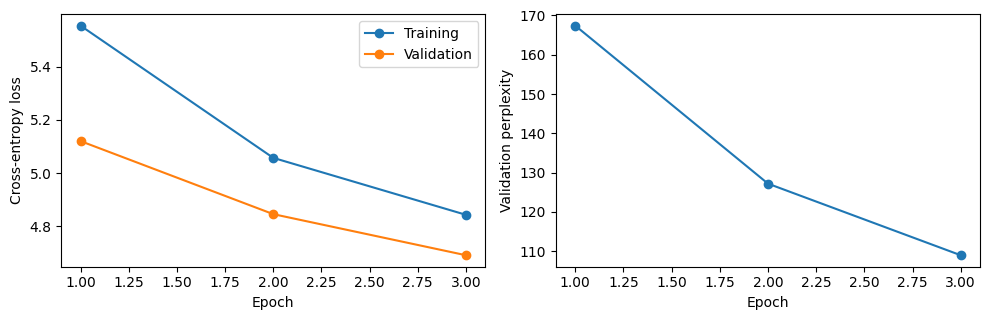

In [19]:
# Plot training/validation loss and validation perplexity to inspect learning and overfitting.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].plot(history_table['epoch'], history_table['train_loss'], 'o-', label='Training')
axes[0].plot(history_table['epoch'], history_table['validation_loss'], 'o-', label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()
axes[1].plot(history_table['epoch'], history_table['validation_perplexity'], 'o-')
axes[1].set(xlabel='Epoch', ylabel='Validation perplexity')
fig.tight_layout()
plt.show()


## Part 5: Evaluation and analysis
### Task 5.1: Predicting the next word


In [20]:
# Return the k most likely next words without building a gradient graph.
@torch.no_grad()
def next_words(model, tokenizer, prompt, k=5):
    model.eval()
    # Omit EOS because the model should continue the prompt rather than treat it as finished.
    ids = tokenizer.encode(prompt, truncation=True, add_eos=False)
    tensor = torch.tensor([ids], device=next(model.parameters()).device)
    # The last prompt position predicts the next token; softmax converts its logits to probabilities.
    probabilities = model(tensor).logits[0, -1].softmax(-1)
    values, indices = probabilities.topk(min(k, len(tokenizer)))
    return [(tokenizer.int_to_str[i.item()], p.item()) for i, p in zip(indices, values)]


In [21]:
# Reload the best validation checkpoint and inspect its next-word predictions.
model = A1RNNModel.from_pretrained(OUTPUT_DIR).to(DEVICE).eval()
prediction_rows = []
for prompt in ['She lives in San', 'The capital of Sweden is']:
    for word, probability in next_words(model, tokenizer, prompt, k=5):
        prediction_rows.append({'prompt': prompt, 'next_word': word, 'probability': probability})
predictions = pd.DataFrame(prediction_rows)
display(predictions)
# Optional file copy of the displayed predictions.
predictions.to_json(OUTPUT_DIR / 'next_words.json', orient='records', indent=2)


,prompt,next_word,probability
0,She lives in San,francisco,0.175850
1,She lives in San,<UNK>,0.158604
2,She lives in San,and,0.023759
3,She lives in San,salvador,0.018775
4,She lives in San,diego,0.009410
5,The capital of Sweden is,the,0.157004
6,The capital of Sweden is,a,0.117293
7,The capital of Sweden is,<UNK>,0.070449
8,The capital of Sweden is,also,0.034426
9,The capital of Sweden is,located,0.027275


### Task 5.2: Validation perplexity
Perplexity is $\exp(\text{mean token cross-entropy})$. Aggregate token losses before
taking the exponential; averaging batch perplexities would give a different quantity.


In [22]:
# Measure loss and perplexity for the reloaded checkpoint on the selected validation set.
trainer.model = model
evaluation = trainer.evaluate()
display(pd.DataFrame([evaluation]))
# Optional file copy of the evaluation already displayed in the notebook.
(OUTPUT_DIR / 'evaluation.json').write_text(json.dumps(evaluation, indent=2))
print('Evaluation mode:', 'small subset; development only' if QUICK_RUN else 'full validation set')


,loss,perplexity,tokens
0,4.691284,108.993029,1306939


Evaluation mode: full validation set


### Task 5.3: Inspecting the learned embeddings
Compare cosine neighbors of several words. The query itself and special tokens are
excluded. Consider whether the neighbors share meaning, topic, or grammatical usage.


In [23]:
# Find words whose learned embedding vectors have the highest cosine similarity to a query word.
@torch.no_grad()
def nearest_neighbors(model, tokenizer, word, n_neighbors=5):
    word = word.lower()
    if word not in tokenizer.str_to_int:
        return []
    index = tokenizer.str_to_int[word]
    # Normalize each embedding to unit length; dot products then equal cosine similarities.
    vectors = F.normalize(model.embedding.weight.float(), dim=-1)
    # Compare the query vector with every vocabulary vector in one matrix-vector product.
    scores = vectors @ vectors[index]
    # Exclude reserved tokens and the query word itself from the neighbor list.
    scores[:4] = -torch.inf
    scores[index] = -torch.inf
    values, indices = scores.topk(min(n_neighbors, max(len(tokenizer) - 5, 0)))
    return [(tokenizer.int_to_str[i.item()], s.item()) for i, s in zip(indices, values)]


In [24]:
# Inspect several query words and display their nearest embedding neighbors.
neighbor_rows = []
for word in ['sweden', 'london', 'large', 'small', 'three']:
    neighbors = nearest_neighbors(model, tokenizer, word, n_neighbors=5)
    if not neighbors:
        print(f'{word!r} is absent from this vocabulary.')
    neighbor_rows.extend({'word': word, 'neighbor': neighbor, 'cosine_similarity': score}
                         for neighbor, score in neighbors)
neighbors_table = pd.DataFrame(neighbor_rows)
display(neighbors_table)
# Optional file copy of the displayed neighbor table.
neighbors_table.to_json(OUTPUT_DIR / 'embedding_neighbors.json', orient='records', indent=2)


,word,neighbor,cosine_similarity
0,sweden,turkey,0.909844
1,sweden,switzerland,0.906145
2,sweden,portugal,0.905571
3,sweden,korea,0.895088
4,sweden,norway,0.894929
5,london,melbourne,0.813271
6,london,michigan,0.794455
7,london,arizona,0.782915
8,london,california,0.781928
9,london,1994,0.777061


### Observations 


Over the three training epochs, training loss decreased from 5.55 to 4.84, while validation loss decreased from 5.12 to 4.69. Validation perplexity improved from 167.41 to 108.99. The third epoch gave the best validation result, and validation performance continued to improve throughout this run.

For “She lives in San”, the highest-probability next word was “francisco”, at approximately 17.6%. Other predictions included “salvador” and “diego”, showing that the model learned some useful word combinations. However, for “The capital of Sweden is”, Stockholm did not appear among the five highest-probability predictions. The frequent appearance of `<UNK>` also shows a limitation of the restricted vocabulary.

The embedding neighbors showed meaningful patterns. “sweden” was close to other country names, and “three” was close to other numbers. Interestingly, “large” and “small” were close despite having opposite meanings. This makes sense because opposite words can appear in similar grammatical contexts. Some neighbors, such as “1994” for “london”, were less intuitive, so the embeddings capture imperfect associations rather than purely semantic similarity.